In [1]:
import os
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt

In [2]:
pth = os.path.join('..', '..')
pth_in = os.path.join(pth, 'data', 'development', 'modeling')
pth_out = os.path.join(pth, 'figures', 'mesencoder')

In [3]:
celltypes = [
    'Epiblast',
    'Posterior Epiblast',
    'Lateral Plate Mesoderm',
    'Neuromesodermal Progenitor',
    'Presomitic Mesoderm']

In [4]:
adata = sc.read_h5ad(os.path.join(pth_in, 'mesencoder.h5ad'))
adata_bif = adata[adata.obs.celltype.isin(celltypes)].copy()
adata_test = adata[adata.obs.mesencoder != 'True'].copy()

In [5]:
palette = {
    'Premigratory Neural Crest'     : plt.cm.tab20c(6),
    'Migratory Neural Crest'        : plt.cm.tab20c(5),
    'Neuroglial Progenitors'        : plt.cm.tab20c(5),
    'Cranial Mesenchyme'            : plt.cm.tab20c(4)}

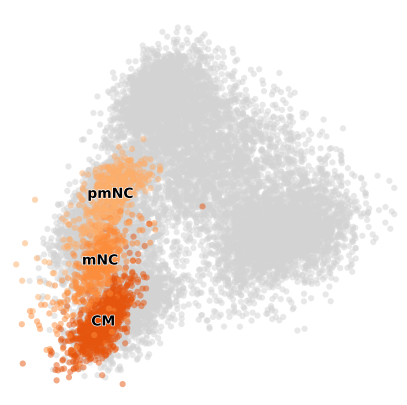

In [7]:
fig, ax = plt.subplots(1, 1, figsize = (5, 5))
sc.pl.embedding(adata_bif, 'X_mesencoder', dimensions = [1, 0],
                size = 80, alpha = .5, frameon = False,
                show = False, ax = ax)
xlim = ax.get_xlim(); ylim = ax.get_ylim()
sc.pl.embedding(adata_test, 'X_mesencoder', dimensions = [1, 0],
                color = 'celltype', size = 80, alpha = .5,
                palette = palette, legend_loc = 'on data',
                legend_fontoutline = 1, frameon = False,
                show = False, ax = ax)
ax.set_title('')
ax.set_ylim(*ylim); ax.invert_yaxis()
ax.set_xlim(xlim[0], xlim[1] - .375)

label_dict = {
    'Premigratory Neural Crest' : 'pmNC',
    'Migratory Neural Crest'    : 'mNC',
    'Neuroglial Progenitors'    : '',
    'Cranial Mesenchyme'        : 'CM'}

for label in ax.texts:
    _label_ = label.get_text()
    if _label_ in label_dict:
        label.set_text(label_dict[_label_])

fn = os.path.join(pth_out, 'testing.pdf')
plt.savefig(fn, bbox_inches = 'tight')

In [7]:
palette = {
    'GSE162534' : plt.cm.tab20c(12),
    'GSE229103' : plt.cm.tab20c(8)}

/home/caleb/miniconda3/envs/scanpy/lib/python3.13/site-packages/scanpy/plotting/_anndata.py:967: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.violinplot(


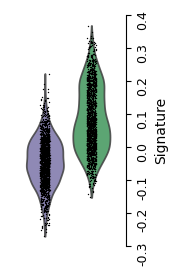

In [8]:
fig, ax = plt.subplots(1, 1, figsize = (1.5, 3))
sc.pl.violin(adata_test, ['GSE162534', 'GSE229103'],
             palette = palette, ylabel = 'Signature',
             alpha = .85, show = False, ax = ax)
ax.set_xticks([])
yticks = np.arange(-.3, .41, .1).round(1)
ax.set_yticks(yticks, labels = yticks)
ax.set_ylim(yticks[0], yticks[-1])
xlim = ax.get_xlim()
ax.set_xlim(xlim[0] - .25, xlim[1] + .25)

for sp in ('left', 'top', 'bottom'):
    ax.spines[sp].set_visible(False)
ax.tick_params('y', left = False, labelleft = False,
               right = True, labelright = True,
               rotation = 90, labelsize = 9)
ax.yaxis.set_label_position('right')

fn = os.path.join(pth_out, 'signatures.pdf')
plt.savefig(fn, bbox_inches = 'tight')